In [1]:
from specml.data_processing import SpectroscopicData
from specml.visualization import plotting
import numpy as np

In [2]:
test_data1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt')
# test_data2 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt')

Data loaded with shape (512, 1664, 754)
{'filename': 'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', 'xpixels': 1664, 'ypixels': 512, 'xtiles': 13, 'ytiles': 4, 'numpts': 754, 'fpasize': 128}
Spectroscopic data loaded successfully.
--------------------------------------------------



In [3]:
print(test_data1.data.shape)

print(test_data1.wavenumbers[0], test_data1.wavenumbers[-1])

test_data1.keep_range(1000, 3500).remove_range(2400,2500)

print(test_data1.wavenumbers[0], test_data1.wavenumbers[-1])

print(test_data1.data.shape)


(512, 1664, 754)
898.6610276699067 3802.917481899262
1002.7977132797242 3498.2212536334996
(512, 1664, 622)


In [4]:
# Example 1: Using Trapezoidal Rule
area_trapz = test_data1.calculate_area(lower=1700, upper=1800, method='trapezoid')
print("Area under each spectrum (Trapezoidal Rule):")
print(area_trapz.shape)

print(test_data1.wavenumbers.shape)

# Example 2: Using Direct Summation (Riemann Sum)
area_direct = test_data1.calculate_area(lower=1700, upper=1800, method='simpson')
print("Area under each spectrum (Direct Summation):")
print(area_direct.shape)


Data flattened and mask applied. Shape of processed data: (851968, 622)
Area under each spectrum (Trapezoidal Rule):
(512, 1664)
(622,)
Data flattened and mask applied. Shape of processed data: (851968, 622)
Area under each spectrum (Direct Summation):
(512, 1664)


In [5]:
from specml.data_processing.mask import create_mask_from_area, apply_mask

mask = create_mask_from_area(area_trapz, threshold=1.5)

print(mask.shape)

masked_data = apply_mask(test_data1.data, mask)

print(masked_data.shape)

test_data1.data = masked_data
test_data1.mask = mask

print(test_data1.mask.shape)

print(test_data1.to_image().shape)

(512, 1664)
(129186, 622)
(512, 1664)
129186 129186
Data reshaped back to 3D with shape (512, 1664, 622)
(512, 1664, 622)


In [6]:
print(test_data1.data.shape)
test_data1.data = test_data1.to_image()
print(test_data1.data.shape)
test_data1.data = test_data1.flatten()
print(test_data1.data.shape)

(129186, 622)
129186 129186
Data reshaped back to 3D with shape (512, 1664, 622)
(512, 1664, 622)
Data flattened and mask applied. Shape of processed data: (129186, 622)
(129186, 622)


Data is flattened. Reshaping it back to 3D.
129186 129186
Data reshaped back to 3D with shape (512, 1664, 622)
Image slice shape: (512, 1664)


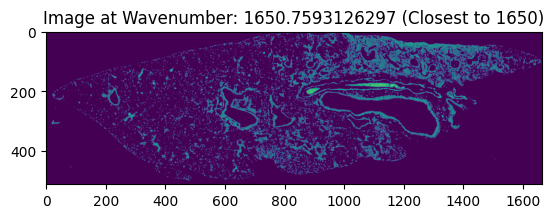

In [7]:
plotting.plot_image_over_wavenumber(test_data1, target_wavenumber=1650)